# 白模转写实：纯 CPU 深度控制生成流水线

本实验参考教师代码附录，自行补全场景、控制图导出和命令行流水线。使用 Blender Cycles CPU、SD-Turbo Q4_0、SD2.1 深度 ControlNet FP16，按场景准备、导图、推理、比较的顺序记录。

A/B/C 三组实验已在本 Notebook 中逐组执行，保留了实际命令、后端日志、生成图片、阶段耗时、进程总耗时和采样得到的峰值工作集。结果分析对应运行会话 `notebook-20261027-222333`，实验条件为 i7-14650HX、Windows、12 线程、512×512 分辨率。

复现时在 VS Code 打开本 Notebook，选择已安装依赖的 **Windows Python** 内核，从上到下执行并保存。首次资源准备见 README；重新执行推理单元会产生新的尝试记录。


## 一、实验目的与环境

掌握从白模导出几何条件、调用量化扩散模型、控制变量比较以及定位几何失真。固定场景、提示词、随机种子、采样器和线程数，只改变步数或控制强度。


In [1]:
from pathlib import Path
import sys, os, json, inspect, platform
from datetime import datetime
from IPython.display import display, Markdown, Code, Image as DisplayImage

assert platform.system() == "Windows", "请选择 Windows Python 内核，本实验使用 Windows CPU 后端。"
candidates = [Path.cwd(), *Path.cwd().parents]
LAB = next((p for p in candidates if (p / "scripts/run_pipeline.py").is_file()), None)
if LAB is None:
    LAB = next((p / "labs/07-cpu-depth-control" for p in candidates
                if (p / "labs/07-cpu-depth-control/scripts/run_pipeline.py").is_file()), None)
assert LAB is not None, "请从本仓库或实验目录打开 Notebook。"
sys.path.insert(0, str(LAB / "scripts"))
from run_pipeline import (RUNTIME, environment, executable, run_logged, prepare_controls,
                          read_controls, run_experiment, public_text, sha256)
import numpy as np
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from PIL import Image

# 固定线程数，避免占满机器所有逻辑线程。全部实验保持相同设置。
THREADS = 12
RUN_SESSION = datetime.now().strftime("notebook-%Y%m%d-%H%M%S")
records, photos = {}, {}
print("本次运行标识：", RUN_SESSION)
print(json.dumps(environment(), ensure_ascii=False, indent=2))
print("CPU 线程数：", THREADS)


本次运行标识： notebook-20261027-222333
{
  "python": "3.13.3",
  "os": "Windows",
  "cpu": "Intel(R) Core(TM) i7-14650HX",
  "physical_cores": 16,
  "logical_cores": 24,
  "ram_gib": 31.71,
  "available_ram_gib": 4.53
}
CPU 线程数： 12


In [2]:
# 验证实际使用的程序；help 不加载模型、不执行推理。
import subprocess
for kind in ("blender", "sdcpp"):
    exe = executable(kind)
    flag = "--version" if kind == "blender" else "--help"
    result = subprocess.run([str(exe), flag], capture_output=True, text=True,
                            encoding="utf-8", errors="replace", check=True)
    print(kind, public_text((result.stdout + result.stderr).splitlines()[0]))
manifest = json.loads((RUNTIME / "resources.json").read_text(encoding="utf-8"))
print("后端提交：", manifest["sdcpp_commit"])
# 完整 SHA256 验证会读取两个模型，需数秒至数十秒。
for name, info in manifest["models"].items():
    model = RUNTIME / "models" / name
    assert model.stat().st_size == info["bytes"]
    assert sha256(model) == info["sha256"], name + " 校验失败"
    print(name, info["bytes"], "bytes; SHA256:", info["sha256"])


blender Blender 4.5.13 LTS
sdcpp stable-diffusion.cpp version unknown, commit be48649
后端提交： be48649
sd_turbo-q4_0.gguf 1741293184 bytes; SHA256: a07f01e9338662c5e057ffd59773b752ac88f833112b120877f909fcbfca776c
control_depth_sd21-fp16.gguf 728482784 bytes; SHA256: 05be8b0abb8ab77af4a882f1647a5db0be4ab76e3d786e61a67ff32ac0ba9e27


## 二、白模场景与控制图

### 2.1 场景生成

场景包含球、圆环、倒角立方体、圆柱与地面；采用 63 mm 相机及三点布光。以下显示实际执行脚本，保留建模、相机和材质实现。


In [3]:
display(Code((LAB / "blender/make_demo_scene.py").read_text(encoding="utf-8"), language="python"))


"""Run with Blender -b -P; scene follows the instructor's appendix A.1."""
import argparse
from pathlib import Path
import sys

import bpy
from mathutils import Vector


def look_at(obj, target):
    obj.rotation_euler = (Vector(target) - obj.location).to_track_quat('-Z', 'Y').to_euler()


def material(name, color, roughness):
    mat = bpy.data.materials.new(name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get('Principled BSDF')
    bsdf.inputs['Base Color'].default_value = (*color, 1)
    bsdf.inputs['Roughness'].default_value = roughness
    return mat


def add_area_light(name, location, energy, size, target):
    data = bpy.data.lights.new(name, type='AREA')
    data.energy, data.size = energy, size
    obj = bpy.data.objects.new(name, data)
    bpy.context.collection.objects.link(obj)
    obj.location = location
    look_at(obj, target)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--output', required=True)
    args = parser.parse_args(sys.argv[sys.argv.index('--') + 1:] if '--' in sys.argv else [])
    bpy.ops.wm.read_factory_settings(use_empty=True)
    scene = bpy.context.scene
    scene.render.engine = 'CYCLES'
    scene.cycles.device = 'CPU'
    scene.cycles.samples = 64
    scene.cycles.use_denoising = True
    scene.render.resolution_x = scene.render.resolution_y = 512
    scene.render.resolution_percentage = 100
    scene.world = bpy.data.worlds.new('World')
    scene.world.use_nodes = True
    scene.world.node_tree.nodes['Background'].inputs[0].default_value = (0.15, 0.15, 0.15, 1)
    body = material('White matte', (0.8, 0.8, 0.8), 0.7)
    floor_mat = material('Floor', (0.65, 0.65, 0.65), 0.8)
    bpy.ops.mesh.primitive_plane_add(size=24)
    bpy.context.object.name = 'Floor'
    bpy.context.object.data.materials.append(floor_mat)
    bpy.ops.mesh.primitive_uv_sphere_add(radius=0.62, segments=64, ring_count=32,
                                        location=(-0.95, 0, 0.62))
    sphere = bpy.context.object
    sphere.name = 'Sphere'
    bpy.ops.object.shade_smooth()
    bpy.ops.mesh.primitive_cube_add(size=1.05, location=(0.55, 0.15, 0.525))
    cube = bpy.context.object
    cube.name = 'BeveledCube'
    bevel = cube.modifiers.new('Bevel', 'BEVEL')
    bevel.width, bevel.segments = 0.09, 4
    bpy.ops.mesh.primitive_cylinder_add(vertices=64, radius=0.37, depth=1.25,
                                       location=(1.6, 0.65, 0.625))
    bpy.context.object.name = 'Cylinder'
    bpy.ops.object.shade_smooth()
    bpy.ops.mesh.primitive_torus_add(major_radius=0.44, minor_radius=0.15,
                                    major_segments=64, minor_segments=24,
                                    location=(-0.15, 1.25, 0.59),
                                    rotation=(1.57079632679, 0, 0))
    bpy.context.object.name = 'Torus'
    bpy.ops.object.shade_smooth()
    for obj in scene.objects:
        if obj.type == 'MESH' and obj.name != 'Floor':
            obj.data.materials.append(body)
    camera_data = bpy.data.cameras.new('Camera')
    camera_data.lens = 63
    camera = bpy.data.objects.new('Camera', camera_data)
    bpy.context.collection.objects.link(camera)
    camera.location = (4.8, -6, 2.8)
    look_at(camera, (0, 0, 0.55))
    scene.camera = camera
    add_area_light('Key', (3, -3.2, 4.2), 300, 3.5, (0, 0, 0.5))
    add_area_light('Fill', (-3.6, -2.8, 2.2), 80, 5, (0, 0, 0.6))
    add_area_light('Rim', (0.5, 3.5, 3.2), 220, 2.2, (0, 0, 0.8))
    out = Path(args.output).resolve()
    out.parent.mkdir(parents=True, exist_ok=True)
    bpy.ops.wm.save_as_mainfile(filepath=str(out))


if __name__ == '__main__':
    main()

### 2.2 深度、法线和白模导出

按相机视锥内顶点到相机距离的 2%/98% 分位设置线性 Mist 范围，反相得到近亮远暗的深度图。视锥筛选不等同于遮挡可见性测试。法线从 [-1,1] 映射至 [0,1]，仅用于检查朝向。几何数据输出不应用显示色彩变换；clay 使用白色材质覆盖。

三张图共享一次 Cycles CPU 渲染，记录共同的渲染与导出耗时，同时记录 Blender 子进程总耗时，不虚构逐张独立渲染耗时。


In [4]:
display(Code((LAB / "blender/export_control_maps.py").read_text(encoding="utf-8"), language="python"))


"""Export Mist/Normal passes and a white material override in one CPU render."""
import argparse
import json
from pathlib import Path
import sys
import time

import bpy
import numpy as np
from bpy_extras.object_utils import world_to_camera_view


def scene_depth_range(scene, camera):
    # View-frustum filtering follows appendix A.2; it is not an occlusion test.
    depsgraph = bpy.context.evaluated_depsgraph_get()
    distances = []
    for obj in scene.objects:
        if obj.type != 'MESH' or obj.hide_render:
            continue
        evaluated = obj.evaluated_get(depsgraph)
        mesh = evaluated.to_mesh()
        try:
            for vertex in mesh.vertices:
                world = evaluated.matrix_world @ vertex.co
                ndc = world_to_camera_view(scene, camera, world)
                if ndc.z > 0 and 0 <= ndc.x <= 1 and 0 <= ndc.y <= 1:
                    distances.append((world - camera.matrix_world.translation).length)
        finally:
            evaluated.to_mesh_clear()
    if not distances:
        raise RuntimeError('No mesh vertices inside camera frustum; check the camera.')
    near, far = np.percentile(distances, [2, 98]).astype(float)
    return near, far if far > near else near + 1


def make_clay_material():
    mat = bpy.data.materials.new('Clay override')
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes['Principled BSDF']
    bsdf.inputs['Base Color'].default_value = (0.8, 0.8, 0.8, 1)
    bsdf.inputs['Roughness'].default_value = 0.7
    return mat


def setup_compositor(scene, outdir, name):
    scene.use_nodes = True
    tree = scene.node_tree
    tree.nodes.clear()
    render = tree.nodes.new('CompositorNodeRLayers')
    invert = tree.nodes.new('CompositorNodeInvert')
    invert.inputs['Fac'].default_value = 1
    tree.links.new(render.outputs['Mist'], invert.inputs['Color'])
    multiply = tree.nodes.new('CompositorNodeMixRGB')
    multiply.blend_type = 'MULTIPLY'
    multiply.inputs[0].default_value = 1
    multiply.inputs[2].default_value = (0.5, 0.5, 0.5, 1)
    add = tree.nodes.new('CompositorNodeMixRGB')
    add.blend_type = 'ADD'
    add.inputs[0].default_value = 1
    add.inputs[2].default_value = (0.5, 0.5, 0.5, 1)
    tree.links.new(render.outputs['Normal'], multiply.inputs[1])
    tree.links.new(multiply.outputs[0], add.inputs[1])
    for suffix, socket in [('depth', invert.outputs[0]), ('normal', add.outputs[0])]:
        output = tree.nodes.new('CompositorNodeOutputFile')
        output.base_path = str(outdir)
        output.file_slots[0].path = f'{name}_{suffix}_'
        output.format.file_format = 'PNG'
        output.format.color_mode = 'RGB'
        output.format.color_depth = '8'
        # Raw override is required even for PNG: save_as_render=False alone
        # still applies the output sRGB transfer (linear 0.5 becomes ~188).
        output.format.color_management = 'OVERRIDE'
        output.format.view_settings.view_transform = 'Raw'
        output.format.view_settings.look = 'None'
        output.format.view_settings.exposure = 0
        output.format.view_settings.gamma = 1
        output.save_as_render = True
        tree.links.new(socket, output.inputs[0])
    composite = tree.nodes.new('CompositorNodeComposite')
    tree.links.new(render.outputs['Image'], composite.inputs['Image'])


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--outdir', required=True)
    parser.add_argument('--name', default='demo')
    parser.add_argument('--res', type=int, default=512)
    parser.add_argument('--samples', type=int, default=64)
    parser.add_argument('--threads', type=int, default=12)
    args = parser.parse_args(sys.argv[sys.argv.index('--') + 1:])
    outdir = Path(args.outdir).resolve()
    outdir.mkdir(parents=True, exist_ok=True)
    scene = bpy.context.scene
    scene.render.engine = 'CYCLES'
    scene.cycles.device = 'CPU'
    scene.cycles.samples = args.samples
    scene.cycles.use_denoising = True
    scene.render.threads_mo

In [5]:
# 已完成的本地预检可直接读取；修改脚本或场景后应重新导出。
FORCE_RENDER = False
if FORCE_RENDER:
    controls = prepare_controls(res=512, samples=64, threads=THREADS)
else:
    try:
        controls = read_controls(512)
    except (FileNotFoundError, ValueError, KeyError):
        controls = prepare_controls(res=512, samples=64, threads=THREADS)
assert controls["threads"] == THREADS, "线程设置变化，请 FORCE_RENDER=True 后重跑。"
print(json.dumps(controls, ensure_ascii=False, indent=2))
# 展示实际准备命令，去除本地绝对路径中的个人信息。
for filename in ["scene.log", "export.log"]:
    first = (RUNTIME / "output/controls_512" / filename).read_text(encoding="utf-8").splitlines()[0]
    print(public_text(first))


{
  "resolution": 512,
  "samples": 64,
  "threads": 12,
  "near": 7.552913883029471,
  "far": 9.409934727377202,
  "render_and_export_s": 5.885027099982835,
  "timing_note": "clay/depth/normal share one Cycles render; no separate render times",
  "blender_version": "4.5.13 LTS",
  "scene_process": {
    "wall_s": 0.6855444998946041,
    "peak_process_tree_rss_mib": 156.921875
  },
  "export_process": {
    "wall_s": 6.763938599964604,
    "peak_process_tree_rss_mib": 444.16015625
  },
  "script_sha256": {
    "make_demo_scene.py": "39a59db9b5e405471601751208d30d8091d9eed2dfa1aad709afab2a3c1d1605",
    "export_control_maps.py": "3d1cb532bc47d64c9874d6657d9a0a21fd24ae50c5eff0dbb5bf1fe04d6cc7fd"
  },
  "blend_sha256": "07c5499b2f2aba9aa13f032a40580e21a46d1616e2525065e74e4987bc5f99d9",
  "files": {
    "demo_clay.png": {
      "sha256": "b00c5e2509aaac0cc089b4e0a4da0b36b7eb1c026282d9063d2f2770bdda59b4",
      "mode": "RGB",
      "min": 79,
      "max": 215
    },
    "demo_depth_0001.png

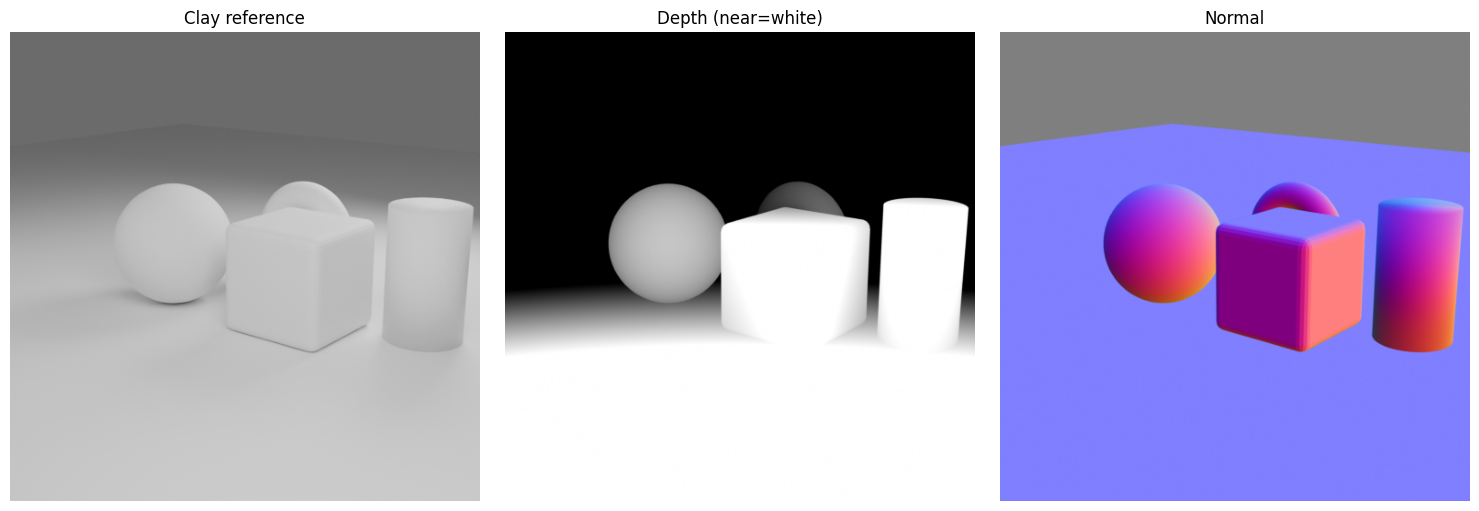

In [6]:
control_dir = RUNTIME / "output/controls_512"
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, suffix, title in zip(axes, ["clay", "depth_0001", "normal_0001"],
                              ["Clay reference", "Depth (near=white)", "Normal"]):
    with Image.open(control_dir / f"demo_{suffix}.png") as im:
        ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 三、CPU 推理与参数对比

| 运行 | 分辨率 | 步数 | CFG | ControlNet 强度 | 比较目的 |
|---|---:|---:|---:|---:|---|
| A | 512×512 | 4 | 1.2 | 0.9 | 基准 |
| B | 512×512 | 8 | 1.2 | 0.9 | 与 A 比较步数 |
| C | 512×512 | 4 | 1.2 | 0.5 | 与 A 比较几何控制强度 |

种子固定为 42，采样器 euler_a、调度器 discrete、随机数生成器 cpu，推理与参数后端均指定 cpu。提示词采用指南配置。B 使用指南允许的 512²/8 步方案满足第二组对比。

每次执行新建独立尝试目录，记录状态、原始日志和图片。峰值内存为每 0.25 秒采样的进程树 RSS，可能漏过短暂峰值，不能等同于模型权重大小。

总耗时指 sd-cli 子进程墙钟耗时，包含加载、编码、采样、解码和写图；共享的 Blender 准备另行记录。


In [7]:
# 检查实际运行实现与命令参数。
display(Code(inspect.getsource(run_experiment), language="python"))
from run_pipeline import PROMPT, NEGATIVE
print("正向提示词：", PROMPT)
print("负向提示词：", NEGATIVE)


def run_experiment(label, steps=4, control_strength=0.9, res=512, cfg=1.2,
                   seed=42, threads=12, session='manual', control_image=None):
    if not re.fullmatch(r'[A-Za-z0-9_-]+', label + session):
        raise ValueError('Use letters, digits, underscores or hyphens for label/session.')
    if res not in (512, 768) or steps < 1 or threads < 1:
        raise ValueError('Invalid resolution, steps or threads.')
    read_controls(res) if control_image is None else None
    models = RUNTIME / 'models'
    main_model = models / 'sd_turbo-q4_0.gguf'
    control_model = models / 'control_depth_sd21-fp16.gguf'
    for model in [main_model, control_model]:
        if not model.is_file() or model.stat().st_size < 100_000_000:
            raise FileNotFoundError(f'Missing/incomplete model: {model.name}')
        with model.open('rb') as f:
            if f.read(4) != b'GGUF':
                raise ValueError(f'Not GGUF: {model.name}')
    manifest = json.loads((RUNTIME / 'resources.json').read_text(encoding='utf-8'))
    for model in [main_model, control_model]:
        if sha256(model) != manifest['models'][model.name]['sha256']:
            raise ValueError(f'Model checksum changed: {model.name}')
    attempt = datetime.now().strftime('%Y%m%d-%H%M%S') + '-' + uuid.uuid4().hex[:6]
    out = RUNTIME / 'output' / session / f'{label}-{attempt}'
    out.mkdir(parents=True, exist_ok=False)
    source = Path(control_image).resolve() if control_image else (
        RUNTIME / 'output' / f'controls_{res}' / 'demo_depth_0001.png')
    depth = out / 'depth.png'
    depth.write_bytes(source.read_bytes())
    ensure_rgb(depth, res)
    photo = out / f'{label}_photoreal.png'
    cli = executable('sdcpp')
    command = [cli, '-m', main_model, '-p', PROMPT, '-n', NEGATIVE,
               '--control-net', control_model, '--control-image', depth,
               '--control-strength', control_strength, '-W', res, '-H', res,
               '--steps', steps, '--cfg-scale', cfg, '--sampling-method', 'euler_a',
               '--scheduler', 'discrete', '--rng', 'cpu', '-s', seed, '-t', threads,
               '--backend', 'cpu', '--params-backend', 'cpu', '-o', photo]
    record = dict(label=label, session=session, attempt=attempt,
                  started_at=datetime.now().astimezone().isoformat(), status='running',
                  resolution=res, steps=steps, cfg=cfg, control_strength=control_strength,
                  seed=seed, threads=threads, sampler='euler_a', scheduler='discrete',
                  rng='cpu', backend='cpu', prompt=PROMPT, negative=NEGATIVE,
                  sdcpp_commit=manifest['sdcpp_commit'], models=manifest['models'],
                  depth_sha256=sha256(depth), environment=environment(),
                  photo=photo.name, log='sd-cli.log',
                  total_timing_scope='sd-cli process wall time; shared Blender preparation excluded')
    dest = out / 'record.json'
    dest.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding='utf-8')
    try:
        timing = run_logged(command, out / 'sd-cli.log', cli.parent)
        if not photo.is_file():
            raise RuntimeError('Backend exited without the requested output image.')
        with Image.open(photo) as img:
            if img.size != (res, res):
                raise RuntimeError('Generated image dimensions differ from requested dimensions.')
        record.update(status='complete', total_s=timing['wall_s'],
                      peak_process_tree_rss_mib=timing['peak_process_tree_rss_mib'],
                      photo_sha256=sha256(photo),
                      **parse_timings((out / 'sd-cli.log').read_text(encoding='utf-8')))
        if record['sampling_s'] is None or record['vae_decode_s'] is None:
            print('阶段耗时未完全识别；保留空值，请按原始日志核对。')
    except BaseException as exc:
        record.update(status='interrupted' if isinstance(exc, KeyboardInterrupt) else 'failed',
                      error=public_text(str(exc)))
     

正向提示词： photorealistic render, studio soft lighting, PBR material, preserve original 3d geometry, sharp
负向提示词： deformed geometry, perspective changed


### 3.1 运行 A：512² / 4 步 / 控制强度 0.9

本组运行已完成。以下保留实际命令、后端日志、结果记录与生成图片。


<local>\sdcpp\sd-cli.exe -m <local>\models\sd_turbo-q4_0.gguf -p "photorealistic render, studio soft lighting, PBR material, preserve original 3d geometry, sharp" -n "deformed geometry, perspective changed" --control-net <local>\models\control_depth_sd21-fp16.gguf --control-image <local>\output\notebook-20261027-222333\A-20261027-222338-ef5497\depth.png --control-strength 0.9 -W 512 -H 512 --steps 4 --cfg-scale 1.2 --sampling-method euler_a --scheduler discrete --rng cpu -s 42 -t 12 --backend cpu --params-backend cpu -o <local>\output\notebook-20261027-222333\A-20261027-222338-ef5497\A_photoreal.png
load_backend: loaded CPU backend from <local>\sdcpp\ggml-cpu-alderlake.dll
[I] loading model from '<local>\models\sd_turbo-q4_0.gguf' --- diffusion_engine.cpp:685
[I] load <local>\models\sd_turbo-q4_0.gguf using gguf format --- model_loader.cpp:216
[I] load <local>\models\control_depth_sd21-fp16.gguf using gguf format --- model_loader.cpp:216
[I] Version: SD 2.x  --- diffusion_engine.cpp:97

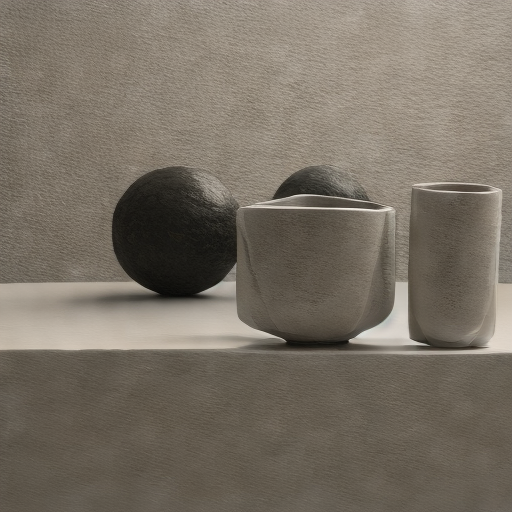

In [8]:
records.pop("A", None)
photos.pop("A", None)
records["A"], photos["A"] = run_experiment(
    "A", steps=4, control_strength=0.9, res=512, cfg=1.2,
    seed=42, threads=THREADS, session=RUN_SESSION)
print(json.dumps(records["A"], ensure_ascii=False, indent=2))
display(DisplayImage(filename=str(photos["A"])))


### 3.2 运行 B：512² / 8 步 / 控制强度 0.9

本组运行已完成。以下保留实际命令、后端日志、结果记录与生成图片。


<local>\sdcpp\sd-cli.exe -m <local>\models\sd_turbo-q4_0.gguf -p "photorealistic render, studio soft lighting, PBR material, preserve original 3d geometry, sharp" -n "deformed geometry, perspective changed" --control-net <local>\models\control_depth_sd21-fp16.gguf --control-image <local>\output\notebook-20261027-222333\B-20261027-222450-229d6a\depth.png --control-strength 0.9 -W 512 -H 512 --steps 8 --cfg-scale 1.2 --sampling-method euler_a --scheduler discrete --rng cpu -s 42 -t 12 --backend cpu --params-backend cpu -o <local>\output\notebook-20261027-222333\B-20261027-222450-229d6a\B_photoreal.png
load_backend: loaded CPU backend from <local>\sdcpp\ggml-cpu-alderlake.dll
[I] loading model from '<local>\models\sd_turbo-q4_0.gguf' --- diffusion_engine.cpp:685
[I] load <local>\models\sd_turbo-q4_0.gguf using gguf format --- model_loader.cpp:216
[I] load <local>\models\control_depth_sd21-fp16.gguf using gguf format --- model_loader.cpp:216
[I] Version: SD 2.x  --- diffusion_engine.cpp:97

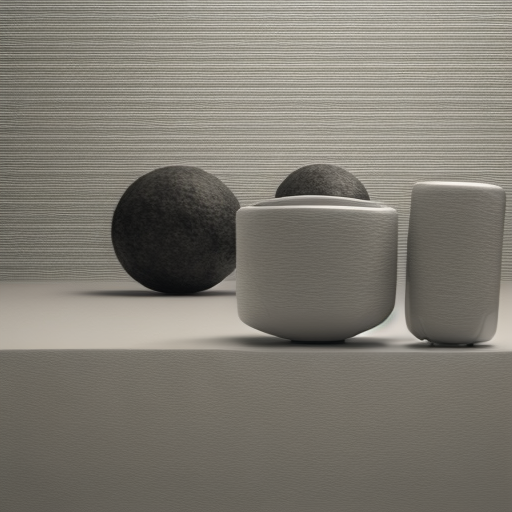

In [9]:
records.pop("B", None)
photos.pop("B", None)
records["B"], photos["B"] = run_experiment(
    "B", steps=8, control_strength=0.9, res=512, cfg=1.2,
    seed=42, threads=THREADS, session=RUN_SESSION)
print(json.dumps(records["B"], ensure_ascii=False, indent=2))
display(DisplayImage(filename=str(photos["B"])))


### 3.3 运行 C：512² / 4 步 / 控制强度 0.5

本组运行已完成。以下保留实际命令、后端日志、结果记录与生成图片。


<local>\sdcpp\sd-cli.exe -m <local>\models\sd_turbo-q4_0.gguf -p "photorealistic render, studio soft lighting, PBR material, preserve original 3d geometry, sharp" -n "deformed geometry, perspective changed" --control-net <local>\models\control_depth_sd21-fp16.gguf --control-image <local>\output\notebook-20261027-222333\C-20261027-222639-4ca88b\depth.png --control-strength 0.5 -W 512 -H 512 --steps 4 --cfg-scale 1.2 --sampling-method euler_a --scheduler discrete --rng cpu -s 42 -t 12 --backend cpu --params-backend cpu -o <local>\output\notebook-20261027-222333\C-20261027-222639-4ca88b\C_photoreal.png
load_backend: loaded CPU backend from <local>\sdcpp\ggml-cpu-alderlake.dll
[I] loading model from '<local>\models\sd_turbo-q4_0.gguf' --- diffusion_engine.cpp:685
[I] load <local>\models\sd_turbo-q4_0.gguf using gguf format --- model_loader.cpp:216
[I] load <local>\models\control_depth_sd21-fp16.gguf using gguf format --- model_loader.cpp:216
[I] Version: SD 2.x  --- diffusion_engine.cpp:97

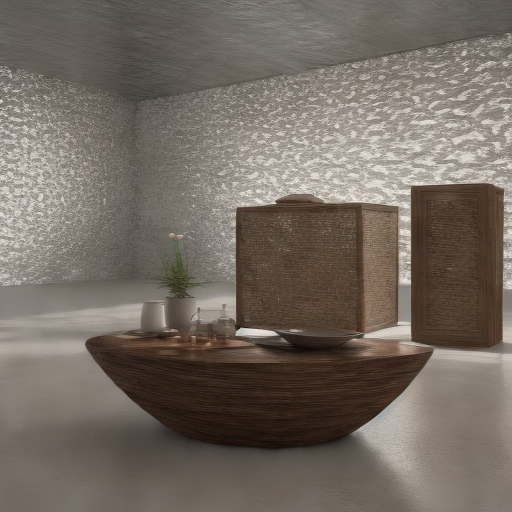

In [10]:
records.pop("C", None)
photos.pop("C", None)
records["C"], photos["C"] = run_experiment(
    "C", steps=4, control_strength=0.5, res=512, cfg=1.2,
    seed=42, threads=THREADS, session=RUN_SESSION)
print(json.dumps(records["C"], ensure_ascii=False, indent=2))
display(DisplayImage(filename=str(photos["C"])))


## 四、结果汇总与分析

仅汇总本次内核中成功执行的 A/B/C 记录。若阶段日志格式变化导致耗时未能识别，保留空值并核对原始日志，不能用总耗时反推阶段耗时冒充实测。


In [11]:
import csv
required = ["A", "B", "C"]
assert all(k in records and records[k]["status"] == "complete" for k in required), "请先完成 A/B/C 三组运行。"
fields = ["label", "resolution", "steps", "cfg", "control_strength", "threads",
          "sampling_s", "vae_decode_s", "total_s", "peak_process_tree_rss_mib"]
rows = [{k: records[label].get(k) for k in fields} for label in required]
headers = ["运行", "分辨率", "步数", "CFG", "Control", "线程", "采样(s)", "VAE(s)", "总耗时(s)", "峰值RSS(MiB)"]
lines = ["|" + "|".join(headers) + "|", "|" + "|".join(["---"] * len(fields)) + "|"]
for row in rows:
    values = ["待核对" if row[k] is None else (f"{row[k]:.2f}" if isinstance(row[k], float) else str(row[k])) for k in fields]
    lines.append("|" + "|".join(values) + "|")
display(Markdown("\n".join(lines)))
summary_dir = RUNTIME / "output" / RUN_SESSION
with (summary_dir / "experiment_results.csv").open("w", encoding="utf-8-sig", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(rows)
(summary_dir / "selected_records.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
print("共享控制图渲染与导出(s)：", controls["render_and_export_s"])
print("共享 Blender 导出进程总耗时(s)：", controls["export_process"]["wall_s"])


|运行|分辨率|步数|CFG|Control|线程|采样(s)|VAE(s)|总耗时(s)|峰值RSS(MiB)|
|---|---|---|---|---|---|---|---|---|---|
|A|512|4|1.20|0.90|12|43.52|17.83|69.77|4082.16|
|B|512|8|1.20|0.90|12|82.45|15.47|106.89|4081.31|
|C|512|4|1.20|0.50|12|38.13|12.85|58.75|4080.67|

共享控制图渲染与导出(s)： 5.885027099982835
共享 Blender 导出进程总耗时(s)： 6.763938599964604


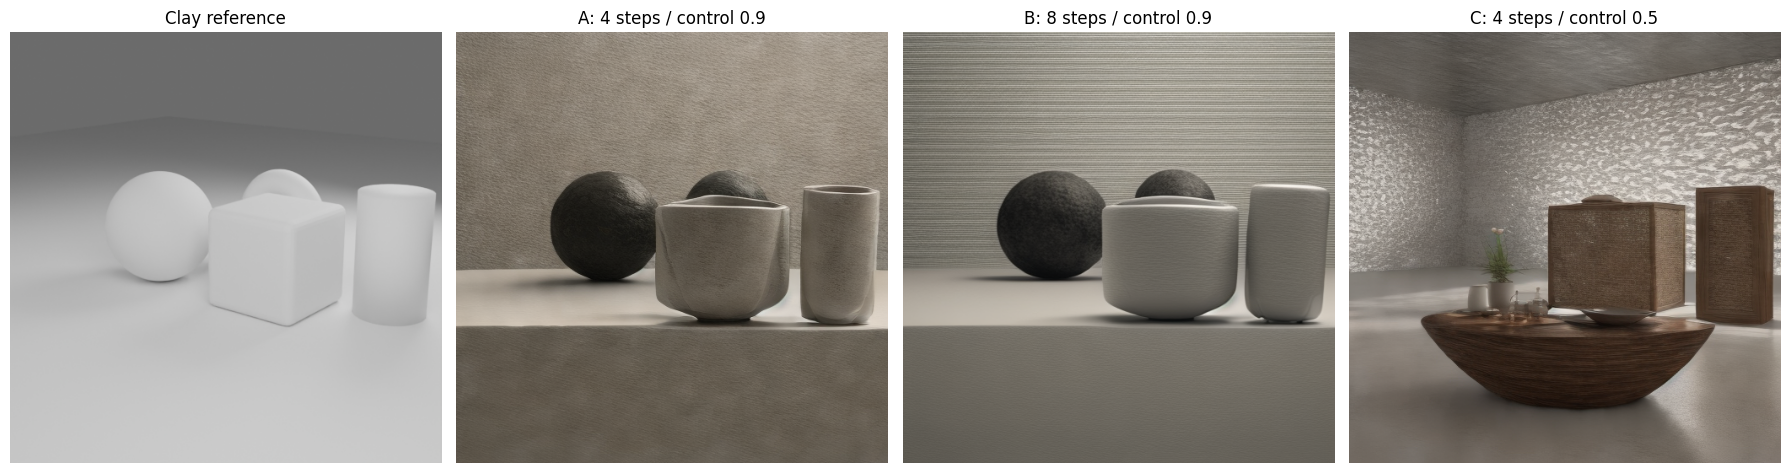

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
with Image.open(control_dir / "demo_clay.png") as im:
    axes[0].imshow(im)
axes[0].set_title("Clay reference")
for ax, label in zip(axes[1:], ["A", "B", "C"]):
    with Image.open(photos[label]) as im:
        ax.imshow(im)
    r = records[label]
    ax.set_title(f"{label}: {r['steps']} steps / control {r['control_strength']}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(summary_dir / "comparison.png", dpi=160, bbox_inches="tight")
plt.show()


In [13]:
a, b, c = (records[k] for k in ["A", "B", "C"])
print(f"B/A 总耗时比：{b['total_s']/a['total_s']:.3f}")
if a['sampling_s'] is not None and b['sampling_s'] is not None:
    print(f"B/A 采样耗时比：{b['sampling_s']/a['sampling_s']:.3f}")
    print(f"A 每步采样耗时：{a['sampling_s']/a['steps']:.3f} s")
    print(f"B 每步采样耗时：{b['sampling_s']/b['steps']:.3f} s")
    print(f"仅按像素数估计 768²/4步采样耗时：{a['sampling_s']*(768/512)**2:.2f} s（推算，未实测）")
print(f"C/A 总耗时比：{c['total_s']/a['total_s']:.3f}")
print("说明：步数改变主要影响采样；加载与 VAE 不应按步数直接翻倍。热状态、缓存与系统负载也可能影响耗时。")


B/A 总耗时比：1.532
B/A 采样耗时比：1.895
A 每步采样耗时：10.880 s
B 每步采样耗时：10.306 s
仅按像素数估计 768²/4步采样耗时：97.92 s（推算，未实测）
C/A 总耗时比：0.842
说明：步数改变主要影响采样；加载与 VAE 不应按步数直接翻倍。热状态、缓存与系统负载也可能影响耗时。


### 4.1 几何保持度评价

A、B 两组基本保持了左侧球体、中央主体、右侧高物体及后方露出部分的相对位置，主要遮挡顺序也与白模接近。但中央倒角立方体被改成圆口容器，平直棱边和方形顶面丢失；A 的右侧圆柱被生成带开口的杯状物。圆环在白模中已被遮挡，生成结果中只剩圆顶，无法确认孔洞得到保留。B 增加到八步后未恢复这些几何细节。C 将控制强度降至 0.5 后，出现大型木碗、编织箱体和室内墙面，左侧球体也未保持。由此可见，较强深度控制有助于稳定整体布局，但本次结果尚未达到精确保留原始几何的程度。

### 4.2 画面质量、失败与问题定位

| 检查项 | 实际观察 | 原因分析与改进方向 |
|---|---|---|
| 立方体结构 | A、B 中央主体均呈圆口容器状，原来的方形棱边与顶面关系消失 | 深度图中部分近处区域已达到白色上限，平面深度差异受压缩；同时深度不能唯一指定物体类别，通用提示词允许模型补成容器。建议先调整深度范围并检查棱边层次，再用明确的形状提示词对比。 |
| 圆环孔洞 | 白模里圆环大部分被前景遮挡，A、B 中后方露出部分变为近似圆顶 | 单视角深度只提供可见表面，遮挡后的孔洞缺少约束。可先调整圆环或相机位置，使孔洞在控制图中清晰可见。 |
| 材质与纹理 | A 的球体呈深色粗糙表面，中央与右侧主体带有陶器般纹理；B 背景出现明显横向重复纹理 | 生成图有明暗与表面质感，但材质并未完全满足理想的写实效果。可能涉及提示词语义、蒸馏模型与采样配置的共同影响，现有实验不能单独归因于量化误差。 |
| 弱控制下的场景偏移 | C 出现木碗、编织箱体、小摆件和室内墙面，物体数量、类别及轮廓均明显变化 | 深度条件减弱后，模型的场景与物体先验占据更大影响。若目标是白模转写实，本场景优先采用 0.9；0.5 更偏向自由重构。 |
| 增加步数的收益 | B 采样耗时增加，但立方体误变容器的问题仍存在，背景重复纹理也未消除 | 增加步数无法补回控制图未包含或已被裁剪的几何信息。应优先检查控制图与模型适配，再考虑增加采样开销。 |

以上原因属于结合控制图和输出作出的解释，尚未通过改深度范围、改构图或更换模型的对照实验验证。当前没有独立几何标注或自动深度重建评估，因此只给出可追溯的视觉评价，不填写无依据的几何准确率。

### 4.3 耗时与内存分析

A、B、C 的采样耗时分别为 **43.52、82.45、38.13 s**，VAE 解码分别为 **17.83、15.47、12.85 s**，总耗时分别为 **69.77、106.89、58.75 s**。采样占各组总耗时约 **62.38%、77.13%、64.90%**，是本次 CPU 流水线的主要时间开销，VAE 解码是第二项主要开销。

从 A 的四步增加到 B 的八步，采样耗时为原来的 **1.895 倍**，总耗时为 **1.532 倍**。A、B 的每步采样耗时分别为 **10.880、10.306 s**，总体符合采样耗时随步数近似线性增加的规律。总耗时没有翻倍，是因为模型加载、文本编码、VAE 和写图等部分不随采样步数同步翻倍。

C 总耗时约为 A 的 **84.22%**，但不能据此认定降低控制强度就能固定加速约 16%。两组的 VAE 解码耗时也有差异，且运行前可用内存分别为 4.38 和 8.04 GiB。控制强度主要改变特征注入权重，当前只各运行一次，未控制缓存、系统负载与热状态，无法分离这些因素的影响。

三组采样观察到的进程树峰值 RSS 分别为 **4082.16、4081.31、4080.67 MiB**，均约 **3.99 GiB**。日志显示模型参数驻留 RAM 为 2357.11 MB、VRAM 为 0；进程工作集还包括计算图、激活和运行库等开销，因此高于权重占用。固定分辨率下，步数翻倍未带来峰值内存的同步增加。

控制图三图共享的渲染与导出为 **5.885 s**，对应 Blender 导出进程总耗时为 **6.764 s**；这些时间与各组 sd-cli 总耗时分别记录。

### 4.4 问题与解决记录

实际准备阶段发现法线 PNG 的默认色彩编码使线性 0.5 分量保存为约 188。将输出节点改为 Raw 色彩管理后重新导图，地面法线像素为 [127,127,255]，符合映射与 8 位量化预期。主模型规范为 FP16 后再转换 Q4_0，最终主模型大小为 1,741,293,184 字节，ControlNet 为 728,482,784 字节；运行前进行了 SHA256 校验。

本次 A/B/C 三组均成功生成图片，原始日志未发现错误或警告。实验中的主要失败属于结果质量问题，即形状被语义改写、圆环孔洞缺失和弱控制下的构图偏移。改深度范围、补充形状提示词及调整构图属于后续改进建议，没有将其写成已经实施的修复。


## 五、思考题

### 1. Turbo 类模型为什么不能使用较高 CFG？CFG 与采样步数是什么关系？

SD-Turbo 通过对抗扩散蒸馏，将多步生成能力压缩到少量网络求值中。常规 CFG 可写为 $\epsilon_g=\epsilon_u+w(\epsilon_c-\epsilon_u)$；较大的 $w$ 会放大条件与无条件预测差异。对没有按高 CFG 方式训练的蒸馏模型继续强外推，可能使采样偏离训练时的分布，导致过饱和、对比度异常或结构失真。[SD-Turbo 官方模型卡](https://huggingface.co/stabilityai/sd-turbo)说明其 Diffusers 用法关闭 CFG 和负向提示词，采用 `guidance_scale=0.0`。本实验保留课程指南规定的 sd-cli `cfg-scale=1.2` 与负向提示词参数；不能将该设置误写成官方 Diffusers 推荐配置。

CFG 控制引导幅度，步数控制沿采样轨迹进行多少次更新，两者没有固定换算关系，增加步数也不能保证补偿过高 CFG。本次 CFG 始终为 1.2，只对比了四步和八步：采样时间从 43.52 s 增至 82.45 s，但立方体误变容器的问题仍存在。因此只验证了本配置下增加步数的成本和有限收益，没有实测高 CFG 的影响。

### 2. 深度图动态范围如何影响生成？Mist 起始距离更小会怎样？

线性 Mist 反相后，在有效范围内可近似表示为 $D(d)=1-\mathrm{clip}((d-s)/L,0,1)$，其中 $s$ 为起始距离，$L$ 为范围长度。本次 $s=7.5529$、远端为 9.4099，范围长度约 1.8570。小于近端的距离被裁剪为白色，大于远端的距离被裁剪为黑色；范围过窄会饱和，范围过宽则会压缩相近表面的灰度差，8 位 PNG 下细微层次也更容易丢失。

本次深度图的近处地面及部分主体出现高亮饱和，生成图中的中央方体缺少棱边约束，这提示需要检查深度分布，而不能只看深度图是否成功导出。视锥顶点的分位数还受网格顶点密度影响，并不等同于所有可见像素的深度分位数。

若只减小起始距离 $s$、保持长度 $L$ 不变，则整个有效距离区间前移，同一表面的反相深度趋暗，远处可能更早被裁为黑色；若保持远端不变并相应增大 $L$，则有效范围变宽，原来近端饱和的部分可能恢复层次，但单位距离对应的灰度差减小。必须说明同时固定了哪个参数。本次没有实际改变 Mist 参数，这部分属于原理分析。

### 3. ControlNet 强度 0.9 与 0.5 有何差别？如何与初始图信息权衡？

A/C 同为 512²、四步、CFG 1.2、种子 42，区别是控制强度由 0.9 降到 0.5。A 基本保持左球、中央主体及右侧高物体的布局，但中央立方体仍被改为圆口容器；C 则出现木碗、编织箱体和室内墙面，原来的球体及原始构图没有得到稳定保留。本次结果说明较强控制有助于维持布局，但不能保证拓扑与棱边严格一致。0.9 并不表示 90% 的几何正确率，也不表示完全覆盖其他条件。

本次使用文本加深度生成，没有输入 img2img 初始图。若拓展到 img2img，初始图先编码为潜变量，去噪强度决定保留原图外观的大致程度，ControlNet 强度决定深度特征施加的约束。通常可用较低去噪强度保留外观，再调整深度控制稳定结构；过强控制或互相矛盾的初始图与深度条件也可能限制自然重绘。该权衡未在本次实测。

### 4. 纯 CPU 推理的主要瓶颈是什么？如何根据分辨率和步数估算耗时？

三组日志中采样占总耗时约 62%～77%，其中重复执行扩散网络及 ControlNet 的计算是主要开销；VAE 解码占约 14%～26%，是另一项明显开销。CPU 的矩阵运算、卷积计算和内存访问都会影响耗时，本次没有硬件计数器测试，不能进一步断言只受某一种资源限制。

可作近似估计：$T\approx kWHN+T_{\mathrm{VAE}}(W,H)+T_{\mathrm{other}}$。由 A 组得到 $k=43.52/(512\times512\times4)\approx4.1504\times10^{-5}$ 秒/(像素·步)。因此按像素线性关系估算，768²/四步的采样约为 $43.52\times(768/512)^2=97.92$ s；这只是推算，未实际运行 768²。模型加载等开销不能全部按像素数放大，高分辨率下的注意力、内存和缓存行为也可能使实际时间偏离该估计。

A/B 的采样比为 1.895、总耗时比为 1.532，与“采样大致随步数线性增长，固定开销不随步数翻倍”的解释相符。由于每组仅一次，不能据此给出稳定的性能区间。

### 5. 为什么使用预乘 alpha？不做预乘会有什么视觉问题？

缩放会对相邻像素插值。如果透明区域仍保存白色 RGB，直接对原始颜色插值，白底会污染半透明边缘，合成后形成亮边或白圈。预乘方法先计算 $P=\alpha C$，再分别缩放 $P$ 和 $\alpha$，最后用 $P'+(1-\alpha')B$ 合成背景；若需要普通 RGB，则仅在 $\alpha'$ 足够大时计算 $C'=P'/\alpha'$，避免除零和放大数值误差。

预乘处理解决透明区颜色参与插值的问题；白底软抠图、边缘内缩与羽化负责估计和修整遮罩，亮度对齐、接触阴影、Poisson 融合及颗粒匹配分别用于改善光色、接触关系和纹理衔接，不能互相替代。本次未进行人像融合，此题依据附录算法作原理分析。

### 6. 同一张脸在不同种子、姿态下保持一致，有哪些路线及代价？

| 路线 | 保持身份的方法 | 主要代价与局限 |
|---|---|---|
| 几何贴图、局部合成与低强度 img2img | 显式保留参考人脸像素，再重绘边缘与光色 | 近似姿态下较直接，但大角度转头需要新视角或形变，容易出现贴图感；提高重绘强度又可能改变身份。 |
| IP-Adapter、身份特征适配器或 InstantID | 用参考图像特征或人脸身份特征作为额外生成条件，并可配合关键点、姿态或深度控制 | 可减少每个身份的专门训练，但需要额外编码器、适配权重及兼容的底模，增加内存和推理成本；不同姿态下仍可能漂移。 |
| DreamBooth 或结合 LoRA 的身份微调 | 用同一人的多张图片学习身份；LoRA 通过低秩参数减少需要更新和保存的权重 | 需要有权限的身份照片、训练时间及调参；LoRA 通常比全量微调更省存储，但仍有过拟合、姿态覆盖不足和身份数据管理成本。 |

固定随机种子只能帮助在同一配置下复现，不能代替身份条件，也不能保证换姿态后仍是同一张脸。本次仅有几何体实验，以上路线未训练或运行，且不能假定这些适配器可直接接入当前 SD2.1 CPU 配置。[IP-Adapter 项目](https://ip-adapter.github.io/)、[InstantID 项目](https://instantid.github.io/)、[DreamBooth 项目](https://dreambooth.github.io/)可作为相应原理来源。


## 六、结论与完成情况

本次完成了白模场景生成、clay/depth/normal 三图导出、纯 CPU 深度控制推理和三组参数比较，保留了实际代码、命令、日志、图片与耗时。使用 Q4_0 主模型和 FP16 SD2.1 ControlNet 后，在本机 12 线程配置下，512²/四步基准运行总耗时为 69.77 s，采样观察到的进程树峰值 RSS 约 3.99 GiB。

增加到八步使采样耗时上升至 82.45 s、总耗时上升至 106.89 s，但没有恢复中央方体的棱边；降低控制强度到 0.5 后，虽然图像仍有材质和光照，原来的几何布局与物体类别却明显偏移。就本场景与当前参数而言，0.9 比 0.5 更适合约束布局，增加步数的收益不足以解决输入几何信息缺失的问题。

本实验的局限是只使用一个场景、一个种子，每组运行一次，未对 CFG、量化精度和分辨率分别作完整消融；没有定量几何真值，也没有完成可选头像融合。后续优先改进可见构图和深度范围，再比较形状提示词与控制强度；这些方向尚未验证。

必做内容已覆盖：512²/四步与 512²/八步对比、额外的控制强度对比、四类图片、阶段与总耗时、几何保持度评价、实际瑕疵及原因、六道思考题。Notebook 内容已形成实验记录，报告填写和代码发布另按课程工作流处理。

模型与后端来源：

- [stable-diffusion.cpp](https://github.com/leejet/stable-diffusion.cpp)，固定提交 `be48649`。
- [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo)。
- [SD2.1 ControlNet](https://huggingface.co/thibaud/controlnet-sd21)。
- [Blender 4.5 官方发布目录](https://download.blender.org/release/Blender4.5/)。
